In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, RobustScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
import warnings


In [2]:
df=pd.read_csv('customer_features.csv')

In [3]:
df.columns

Index(['Customer ID', 'NumOrders', 'TotalSpent', 'AvgOrderValue',
       'StdOrderValue', 'MinOrderValue', 'MaxOrderValue', 'TotalQuantity',
       'AvgQuantityPerOrder', 'UniqueProducts', 'FirstPurchase',
       'LastPurchase', 'Country', 'CustomerLifetimeDays',
       'AvgDaysBetweenOrders', 'ProductDiversityPerOrder', 'IsUK',
       'TotalSpent_log', 'AvgOrderValue_log', 'Recency'],
      dtype='object')

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4285 entries, 0 to 4284
Data columns (total 20 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Customer ID               4285 non-null   float64
 1   NumOrders                 4285 non-null   int64  
 2   TotalSpent                4285 non-null   float64
 3   AvgOrderValue             4285 non-null   float64
 4   StdOrderValue             2872 non-null   float64
 5   MinOrderValue             4285 non-null   float64
 6   MaxOrderValue             4285 non-null   float64
 7   TotalQuantity             4285 non-null   int64  
 8   AvgQuantityPerOrder       4285 non-null   float64
 9   UniqueProducts            4285 non-null   int64  
 10  FirstPurchase             4285 non-null   object 
 11  LastPurchase              4285 non-null   object 
 12  Country                   4285 non-null   object 
 13  CustomerLifetimeDays      4285 non-null   int64  
 14  AvgDaysB

In [5]:

# WEEK 2 - DAY 1: Data Preparation & Scaling for Clustering
# E-Commerce Customer Analytics Platform

warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['figure.figsize'] = (12, 6)

print("=" * 60)
print("STEP 1: Loading customer_features.csv")
print("=" * 60)

df = pd.read_csv('customer_features.csv')
print(f"Shape: {df.shape}")
print(f"\nFirst look:\n{df.head(3)}")


STEP 1: Loading customer_features.csv
Shape: (4285, 20)

First look:
   Customer ID  NumOrders  TotalSpent  AvgOrderValue  StdOrderValue  \
0      12346.0          2      169.36          84.68      81.501128   
1      12347.0          2     1323.32         661.66      70.894526   
2      12348.0          1      221.16         221.16            NaN   

   MinOrderValue  MaxOrderValue  TotalQuantity  AvgQuantityPerOrder  \
0          27.05         142.31             24                 12.0   
1         611.53         711.79            828                414.0   
2         221.16         221.16            372                372.0   

   UniqueProducts        FirstPurchase         LastPurchase         Country  \
0              24  2010-03-02 13:08:00  2010-06-28 13:53:00  United Kingdom   
1              70  2010-10-31 14:20:00  2010-12-07 14:57:00         Iceland   
2              19  2010-09-27 14:59:00  2010-09-27 14:59:00         Finland   

   CustomerLifetimeDays  AvgDaysBetweenOrder

In [6]:
df['Country'].unique()

array(['United Kingdom', 'Iceland', 'Finland', 'Italy', 'Unspecified',
       'Norway', 'Bahrain', 'Portugal', 'Switzerland', 'Austria',
       'Cyprus', 'Belgium', 'Australia', 'RSA', 'Denmark', 'Spain',
       'Germany', 'France', 'USA', 'Thailand', 'Sweden', 'Greece',
       'Poland', 'Israel', 'United Arab Emirates', 'Singapore', 'Brazil',
       'Japan', 'Netherlands', 'Korea', 'EIRE', 'Channel Islands',
       'Lithuania', 'Canada', 'Malta', 'Nigeria', 'West Indies'],
      dtype=object)

In [7]:
# ============================================================
# Remove Bulk Buyers (wholesale/distributor customers)
# ============================================================

# Define bulk buyer threshold — 99th percentile
p99 = df['AvgQuantityPerOrder'].quantile(0.99)
print(f"99th percentile threshold: {p99:.1f} items per order")

# Identify bulk buyers from original df
bulk_mask = df['AvgQuantityPerOrder'] > p99
print(f"Bulk buyers identified: {bulk_mask.sum()} customers")
print(f"\nTheir AvgQuantityPerOrder values:")
print(df[bulk_mask]['AvgQuantityPerOrder'].sort_values(ascending=False).values)

# Save bulk buyers separately before removing
df[bulk_mask].to_csv('bulk_buyers_removed.csv', index=False)
print(f"\nSaved removed customers to: bulk_buyers_removed.csv")

# Remove from df — everything else rebuilds from df
df = df[~bulk_mask].reset_index(drop=True)
print(f"\nDataset size:")
print(f"  Before: 4,285 customers")
print(f"  Removed:  {bulk_mask.sum()} bulk buyers")
print(f"  After:  {len(df)} customers")

99th percentile threshold: 1385.0 items per order
Bulk buyers identified: 43 customers

Their AvgQuantityPerOrder values:
[87167.         44119.2        17766.         17565.6
 15164.8         3976.875       3878.          3517.5
  3199.          2893.5         2851.          2666.66666667
  2574.          2500.          2404.          2390.
  2331.89041096  2241.25        2232.          2220.
  2191.4137931   2189.          2103.85714286  2020.55555556
  1984.61538462  1907.66666667  1898.          1777.64516129
  1753.          1720.          1676.5         1658.
  1543.          1500.          1476.          1476.
  1475.4         1460.          1450.          1428.
  1402.          1402.          1395.68539326]

Saved removed customers to: bulk_buyers_removed.csv

Dataset size:
  Before: 4,285 customers
  Removed:  43 bulk buyers
  After:  4242 customers


In [8]:
# ============================================================
# STEP 2: Country → Revenue Tier Encoding
# ============================================================

country_revenue = df.groupby('Country')['TotalSpent'].sum().sort_values(ascending=False)
total_revenue = country_revenue.sum()

print("Revenue by country:")
for country, rev in country_revenue.items():
    pct = rev / total_revenue * 100
    bar = '█' * int(pct / 2)
    print(f"  {country:20s}  £{rev:>12,.0f}  ({pct:5.1f}%)  {bar}")

# UK dominates (84.8%) so hardcode it as High
# Apply cumulative logic only to remaining countries
UK_COUNTRIES = ['United Kingdom']
non_uk_revenue = country_revenue.drop(index=UK_COUNTRIES, errors='ignore')
non_uk_cumulative = non_uk_revenue.cumsum() / non_uk_revenue.sum() * 100

high_countries   = UK_COUNTRIES
medium_countries = non_uk_cumulative[non_uk_cumulative <= 60].index.tolist()
low_countries    = non_uk_cumulative[non_uk_cumulative > 60].index.tolist()

print(f"\nHigh   ({len(high_countries)}):  {high_countries}")
print(f"Medium ({len(medium_countries)}): {medium_countries}")
print(f"Low    ({len(low_countries)}):  {low_countries}")

# Map to numeric: High=2, Medium=1, Low=0
tier_map = {c: 2 for c in high_countries}
tier_map.update({c: 1 for c in medium_countries})
tier_map.update({c: 0 for c in low_countries})

df['CountryRevenueTier'] = df['Country'].map(tier_map).fillna(0).astype(int)

# Verify — should show 3 tiers
print("\nTier distribution:")
print(df['CountryRevenueTier'].value_counts().sort_index(ascending=False))
print("\nExpected:")
print("  2 → ~3,500+ customers (UK)")
print("  1 → ~400   customers (EIRE, Netherlands, Germany)")
print("  0 → ~240   customers (everyone else)")

# Save reference mapping
country_tier_ref = pd.DataFrame({
    'Country'      : list(tier_map.keys()),
    'RevenueTier'  : list(tier_map.values()),
    'TierLabel'    : ['High' if v == 2 else 'Medium' if v == 1 else 'Low'
                      for v in tier_map.values()],
    'TotalRevenue' : [country_revenue.get(c, 0) for c in tier_map.keys()],
    'RevenueShare%': [(country_revenue.get(c, 0) / total_revenue * 100).round(2)
                      for c in tier_map.keys()]
})
country_tier_ref = country_tier_ref.sort_values('RevenueTier', ascending=False)
print("\n", country_tier_ref.to_string(index=False))
country_tier_ref.to_csv('country_tier_reference.csv', index=False)
print("\nSaved: country_tier_reference.csv")

Revenue by country:
  United Kingdom        £   6,515,624  ( 87.6%)  ███████████████████████████████████████████
  EIRE                  £     334,240  (  4.5%)  ██
  Germany               £     175,594  (  2.4%)  █
  France                £     102,469  (  1.4%)  
  Sweden                £      31,524  (  0.4%)  
  Spain                 £      29,782  (  0.4%)  
  Channel Islands       £      24,346  (  0.3%)  
  Portugal              £      21,380  (  0.3%)  
  Belgium               £      19,298  (  0.3%)  
  Switzerland           £      18,969  (  0.3%)  
  Netherlands           £      18,450  (  0.2%)  
  Denmark               £      16,063  (  0.2%)  
  Italy                 £      13,504  (  0.2%)  
  Austria               £      11,554  (  0.2%)  
  Cyprus                £      11,360  (  0.2%)  
  Greece                £      11,202  (  0.2%)  
  Australia             £      11,016  (  0.1%)  
  Japan                 £       8,188  (  0.1%)  
  Norway                £       7,

In [9]:
# ============================================================
# STEP 2: Country → Revenue Tier Encoding
# ============================================================

country_revenue = df.groupby('Country')['TotalSpent'].sum().sort_values(ascending=False)
total_revenue = country_revenue.sum()

print("Revenue by country:")
for country, rev in country_revenue.items():
    pct = rev / total_revenue * 100
    bar = '█' * int(pct / 2)
    print(f"  {country:20s}  £{rev:>12,.0f}  ({pct:5.1f}%)  {bar}")

# UK dominates (84.8%) so hardcode it as High
UK_COUNTRIES = ['United Kingdom']
non_uk_revenue = country_revenue.drop(index=UK_COUNTRIES, errors='ignore')
non_uk_cumulative = non_uk_revenue.cumsum() / non_uk_revenue.sum() * 100

high_countries   = UK_COUNTRIES
medium_countries = non_uk_cumulative[non_uk_cumulative <= 60].index.tolist()
low_countries    = non_uk_cumulative[non_uk_cumulative > 60].index.tolist()

print(f"\nHigh   ({len(high_countries)}):  {high_countries}")
print(f"Medium ({len(medium_countries)}): {medium_countries}")
print(f"Low    ({len(low_countries)}):  {low_countries}")

# Map to numeric: High=2, Medium=1, Low=0
tier_map = {c: 2 for c in high_countries}
tier_map.update({c: 1 for c in medium_countries})
tier_map.update({c: 0 for c in low_countries})

df['CountryRevenueTier'] = df['Country'].map(tier_map).fillna(0).astype(int)

# Verify
print("\nTier distribution:")
print(df['CountryRevenueTier'].value_counts().sort_index(ascending=False))

# Save reference mapping
country_tier_ref = pd.DataFrame({
    'Country'      : list(tier_map.keys()),
    'RevenueTier'  : list(tier_map.values()),
    'TierLabel'    : ['High' if v == 2 else 'Medium' if v == 1 else 'Low'
                      for v in tier_map.values()],
    'TotalRevenue' : [country_revenue.get(c, 0) for c in tier_map.keys()],
    'RevenueShare%': [(country_revenue.get(c, 0) / total_revenue * 100).round(2)
                      for c in tier_map.keys()]
})
country_tier_ref = country_tier_ref.sort_values('RevenueTier', ascending=False)
print(country_tier_ref.to_string(index=False))
country_tier_ref.to_csv('country_tier_reference.csv', index=False)
print("\nSaved: country_tier_reference.csv")

# ============================================================
# STEP 3: Select Final Feature Set
# ============================================================

DROP_COLS = [
    'Customer ID',
    'FirstPurchase',
    'LastPurchase',
    'Country',       # replaced by CountryRevenueTier
    'IsUK',          # redundant with CountryRevenueTier
    'TotalSpent',    # replaced by TotalSpent_log
    'AvgOrderValue', # replaced by AvgOrderValue_log
]

df_features = df.drop(columns=DROP_COLS)

print(f"\nFeature set ({df_features.shape[1]}):")
for col in df_features.columns:
    print(f"  {col}")

Revenue by country:
  United Kingdom        £   6,515,624  ( 87.6%)  ███████████████████████████████████████████
  EIRE                  £     334,240  (  4.5%)  ██
  Germany               £     175,594  (  2.4%)  █
  France                £     102,469  (  1.4%)  
  Sweden                £      31,524  (  0.4%)  
  Spain                 £      29,782  (  0.4%)  
  Channel Islands       £      24,346  (  0.3%)  
  Portugal              £      21,380  (  0.3%)  
  Belgium               £      19,298  (  0.3%)  
  Switzerland           £      18,969  (  0.3%)  
  Netherlands           £      18,450  (  0.2%)  
  Denmark               £      16,063  (  0.2%)  
  Italy                 £      13,504  (  0.2%)  
  Austria               £      11,554  (  0.2%)  
  Cyprus                £      11,360  (  0.2%)  
  Greece                £      11,202  (  0.2%)  
  Australia             £      11,016  (  0.1%)  
  Japan                 £       8,188  (  0.1%)  
  Norway                £       7,

In [10]:
# UK dominates so heavily it needs its own tier
UK_COUNTRIES = ['United Kingdom']

# Apply cumulative logic only to non-UK countries
non_uk_revenue = country_revenue.drop(index=UK_COUNTRIES, errors='ignore')
non_uk_cumulative = non_uk_revenue.cumsum() / non_uk_revenue.sum() * 100

high_countries   = UK_COUNTRIES
medium_countries = non_uk_cumulative[non_uk_cumulative <= 60].index.tolist()
low_countries    = non_uk_cumulative[non_uk_cumulative > 60].index.tolist()

print(f"High   ({len(high_countries)}):  {high_countries}")
print(f"Medium ({len(medium_countries)}): {medium_countries}")
print(f"Low    ({len(low_countries)}):  {low_countries}")

High   (1):  ['United Kingdom']
Medium (2): ['EIRE', 'Germany']
Low    (34):  ['France', 'Sweden', 'Spain', 'Channel Islands', 'Portugal', 'Belgium', 'Switzerland', 'Netherlands', 'Denmark', 'Italy', 'Austria', 'Cyprus', 'Greece', 'Australia', 'Japan', 'Norway', 'United Arab Emirates', 'Finland', 'Unspecified', 'Lithuania', 'USA', 'Singapore', 'Poland', 'Israel', 'Thailand', 'Malta', 'Iceland', 'Canada', 'Korea', 'RSA', 'Bahrain', 'West Indies', 'Brazil', 'Nigeria']


In [11]:
# ============================================================
# STEP 4: Handle Missing Values
# ============================================================
print("=" * 60)
print("STEP 4: Handling missing values")
print("=" * 60)

# Drop redundant features confirmed in Step 3
REDUNDANT = ['MinOrderValue', 'MaxOrderValue', 'TotalQuantity']
df_features = df_features.drop(columns=[c for c in REDUNDANT if c in df_features.columns])
print(f"Dropped redundant: {REDUNDANT}")
print(f"Feature set now: {df_features.shape[1]} features\n")

# Check missing values
missing = df_features.isnull().sum()
missing_pct = (missing / len(df_features) * 100).round(2)
missing_report = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
missing_report = missing_report[missing_report['Missing Count'] > 0]

if missing_report.empty:
    print("No missing values found!")
else:
    print(missing_report)


STEP 4: Handling missing values
Dropped redundant: ['MinOrderValue', 'MaxOrderValue', 'TotalQuantity']
Feature set now: 11 features

               Missing Count  Missing %
StdOrderValue           1396      32.91


In [12]:

# StdOrderValue NaN = customer placed only 1 order → impute 0
if 'StdOrderValue' in df_features.columns:
    n_missing = df_features['StdOrderValue'].isnull().sum()
    df_features['StdOrderValue'] = df_features['StdOrderValue'].fillna(0)
    print(f"Imputed {n_missing} StdOrderValue NaN → 0 (single-order customers)")

print(f"\nMissing after imputation: {df_features.isnull().sum().sum()}")
print(f"\nFinal 11 features: {list(df_features.columns)}")


Imputed 1396 StdOrderValue NaN → 0 (single-order customers)

Missing after imputation: 0

Final 11 features: ['NumOrders', 'StdOrderValue', 'AvgQuantityPerOrder', 'UniqueProducts', 'CustomerLifetimeDays', 'AvgDaysBetweenOrders', 'ProductDiversityPerOrder', 'TotalSpent_log', 'AvgOrderValue_log', 'Recency', 'CountryRevenueTier']



STEP 5: Correlation analysis
Highly correlated pairs (r > 0.85):
  None — feature set looks clean!


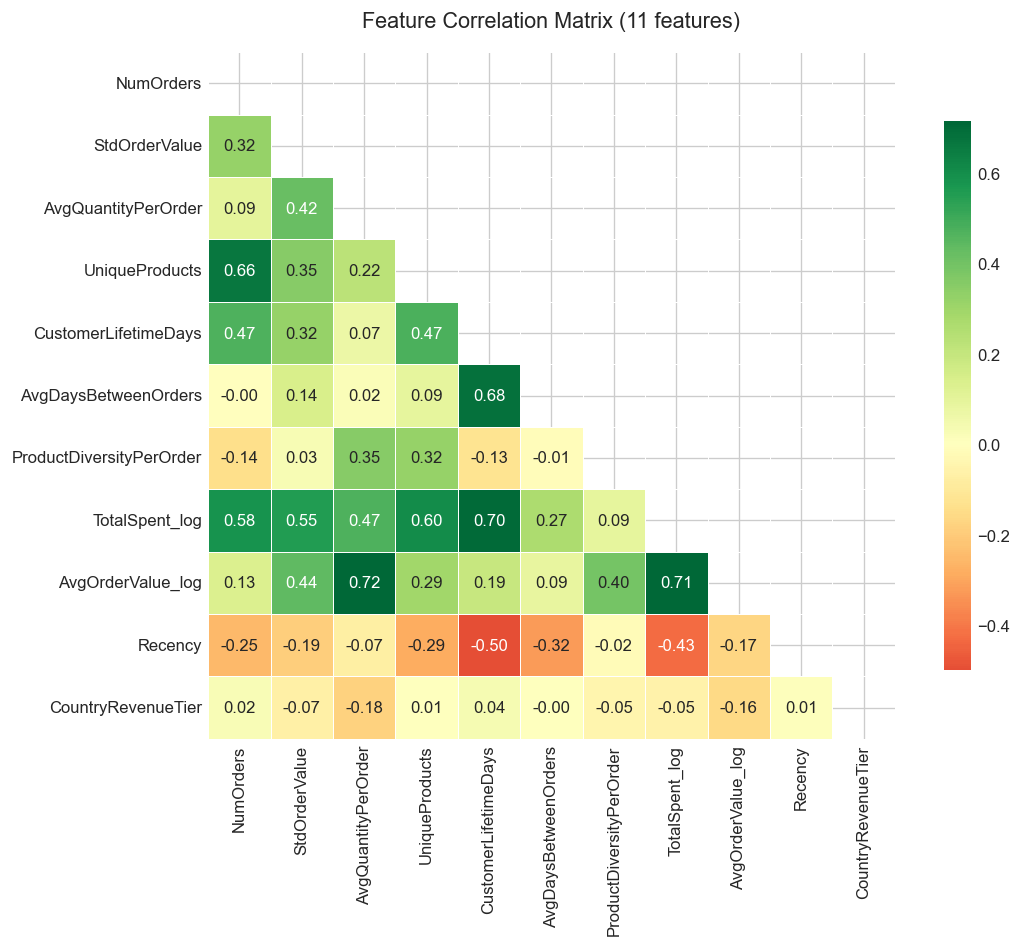

Saved: correlation_heatmap.png


In [13]:

# ============================================================
# STEP 5: Correlation Analysis
# ============================================================
print("\n" + "=" * 60)
print("STEP 5: Correlation analysis")
print("=" * 60)

corr_matrix = df_features.corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

high_corr_pairs = [
    (col, row, upper.loc[row, col])
    for col in upper.columns
    for row in upper.index
    if upper.loc[row, col] > 0.85
]

print("Highly correlated pairs (r > 0.85):")
if high_corr_pairs:
    for f1, f2, r in sorted(high_corr_pairs, key=lambda x: -x[2]):
        print(f"  {f1:30s} ↔ {f2:30s}  r = {r:.3f}")
else:
    print("  None — feature set looks clean!")

# Correlation heatmap
plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(df_features.corr(), dtype=bool))
sns.heatmap(
    df_features.corr(), mask=mask, annot=True, fmt='.2f',
    cmap='RdYlGn', center=0, square=True,
    linewidths=0.5, cbar_kws={'shrink': 0.8}
)
plt.title('Feature Correlation Matrix (11 features)', fontsize=13, pad=15)
plt.tight_layout()
plt.savefig('correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: correlation_heatmap.png")

STEP 6: Scaling


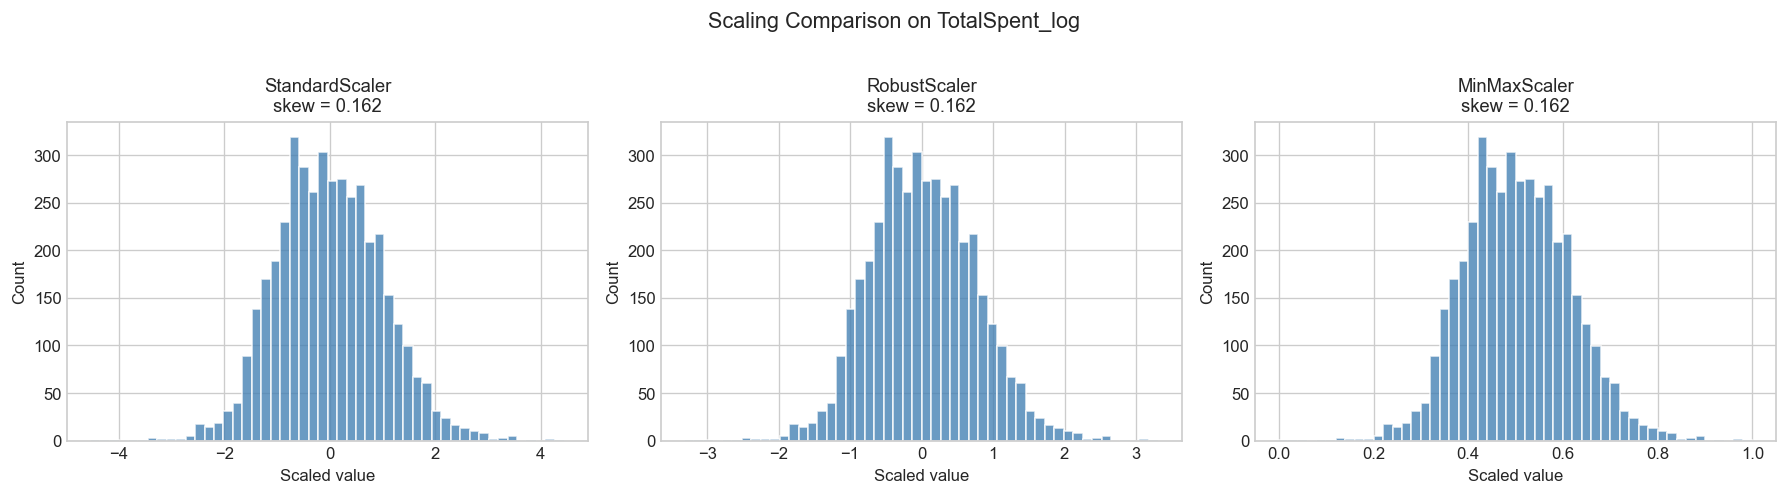

In [14]:
# ============================================================
# STEP 6: Compare Scaling Methods & Apply RobustScaler
# ============================================================
print("=" * 60)
print("STEP 6: Scaling")
print("=" * 60)

from sklearn.preprocessing import StandardScaler, RobustScaler, MinMaxScaler

scalers = {
    'StandardScaler': StandardScaler(),
    'RobustScaler':   RobustScaler(),
    'MinMaxScaler':   MinMaxScaler(),
}

# Visual comparison using TotalSpent_log as demo column
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, scaler) in zip(axes, scalers.items()):
    scaled = scaler.fit_transform(df_features)
    scaled_df = pd.DataFrame(scaled, columns=df_features.columns)
    ax.hist(scaled_df['TotalSpent_log'], bins=50,
            color='steelblue', edgecolor='white', alpha=0.8)
    skew = scaled_df['TotalSpent_log'].skew()
    ax.set_title(f'{name}\nskew = {skew:.3f}', fontsize=11)
    ax.set_xlabel('Scaled value')
    ax.set_ylabel('Count')

plt.suptitle('Scaling Comparison on TotalSpent_log', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig('scaling_comparison.png', dpi=150, bbox_inches='tight')
plt.show()


In [15]:

# Apply RobustScaler — best for skewed data with outliers
scaler = RobustScaler()
features_scaled = scaler.fit_transform(df_features)
features_scaled_df = pd.DataFrame(features_scaled, columns=df_features.columns)

print("Scaled data summary:")
print(features_scaled_df.describe().round(3))

# Save
features_scaled_df.to_csv('features_scaled.csv', index=False)
print("\n✅ Saved: features_scaled.csv")

Scaled data summary:
       NumOrders  StdOrderValue  AvgQuantityPerOrder  UniqueProducts  \
count   4242.000       4242.000             4242.000        4242.000   
mean       0.595          0.366                0.307           0.414   
std        1.941          1.398                1.054           1.377   
min       -0.250         -0.392               -0.908          -0.597   
25%       -0.250         -0.392               -0.368          -0.339   
50%        0.000         -0.000               -0.000           0.000   
75%        0.750          0.608                0.632           0.661   
max       45.250         42.194                7.435          27.403   

       CustomerLifetimeDays  AvgDaysBetweenOrders  ProductDiversityPerOrder  \
count              4242.000              4242.000                  4242.000   
mean                  0.110                 0.156                     0.229   
std                   0.524                 0.684                     1.020   
min           

In [16]:
# Diagnose CountryRevenueTier
print(df_features['CountryRevenueTier'].value_counts())
print(f"\nUnique scaled values: {features_scaled_df['CountryRevenueTier'].unique()}")

CountryRevenueTier
2    3925
0     249
1      68
Name: count, dtype: int64

Unique scaled values: [ 0. -2. -1.]


STEP 7: PCA — Dimensionality Reduction
Components to explain 90% variance: 6
Components to explain 95% variance: 7

Individual explained variance per PC:
  PC 1:  46.0%  cumulative:  46.0%  ██████████████████████████████████████████████
  PC 2:  19.1%  cumulative:  65.1%  ███████████████████
  PC 3:  11.2%  cumulative:  76.3%  ███████████
  PC 4:   7.1%  cumulative:  83.4%  ███████
  PC 5:   6.1%  cumulative:  89.5%  ██████
  PC 6:   3.1%  cumulative:  92.6%  ███
  PC 7:   2.6%  cumulative:  95.2%  ██
  PC 8:   2.3%  cumulative:  97.5%  ██
  PC 9:   1.8%  cumulative:  99.2%  █
  PC10:   0.6%  cumulative:  99.9%  
  PC11:   0.1%  cumulative: 100.0%  


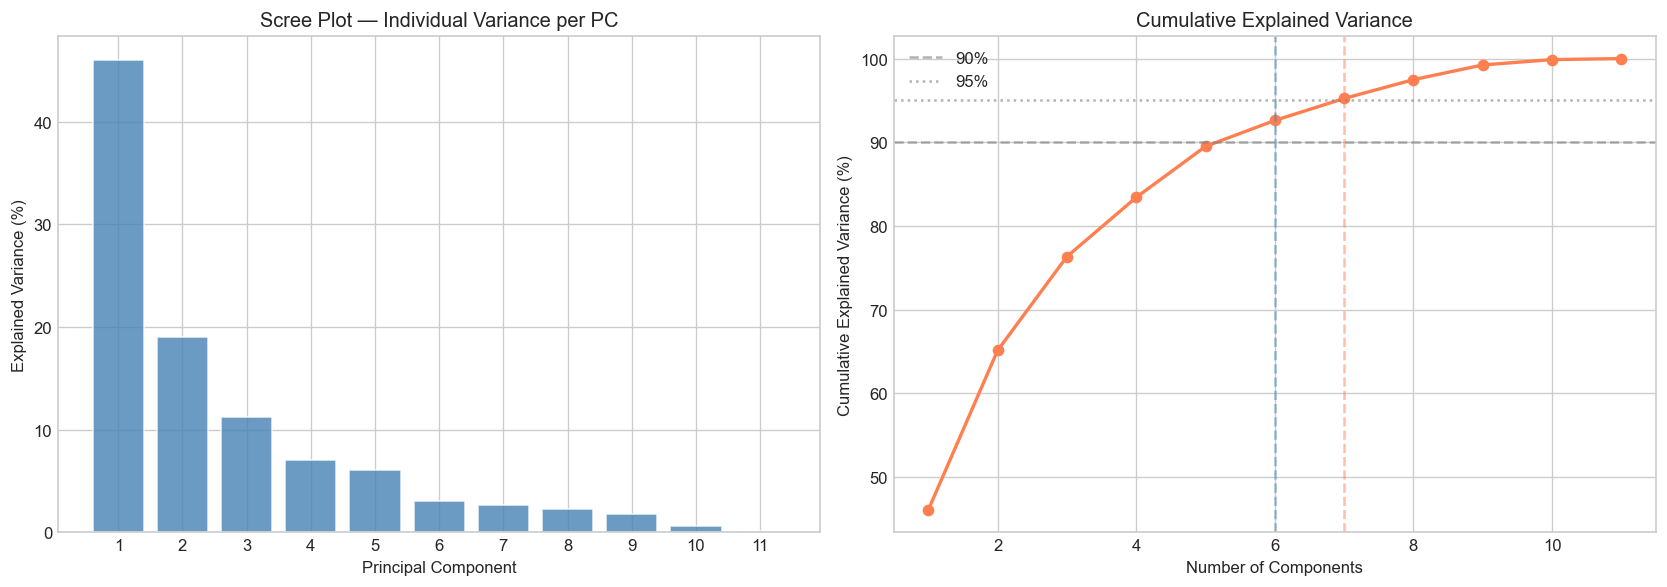

Saved: pca_scree_plot.png

PCA 2D — variance explained:
  PC1: 46.0%
  PC2: 19.1%
  Total: 65.1%

PCA 3D — variance explained:
  PC1: 46.0%
  PC2: 19.1%
  PC3: 11.2%
  Total: 76.3%

PC Loadings (which features drive each component):
                            PC1    PC2
NumOrders                 0.725 -0.480
StdOrderValue             0.340  0.467
AvgQuantityPerOrder       0.150  0.495
UniqueProducts            0.473  0.025
CustomerLifetimeDays      0.127 -0.013
AvgDaysBetweenOrders      0.034  0.057
ProductDiversityPerOrder  0.028  0.361
TotalSpent_log            0.241  0.144
AvgOrderValue_log         0.143  0.384
Recency                  -0.124 -0.025
CountryRevenueTier       -0.005 -0.052


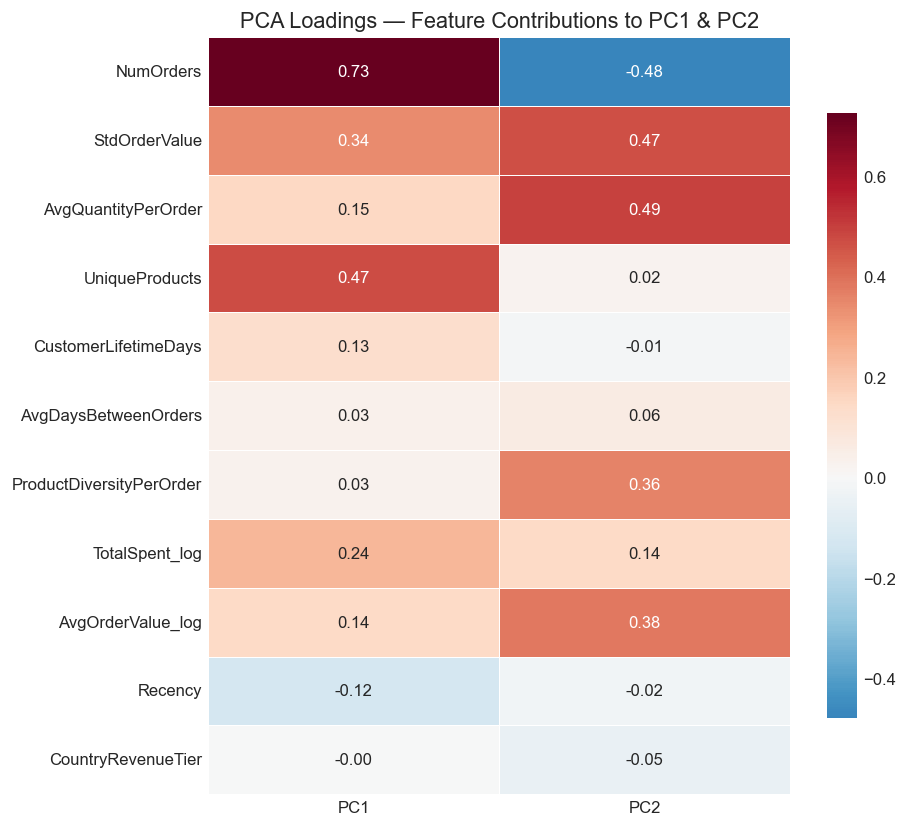

Saved: pca_loadings.png


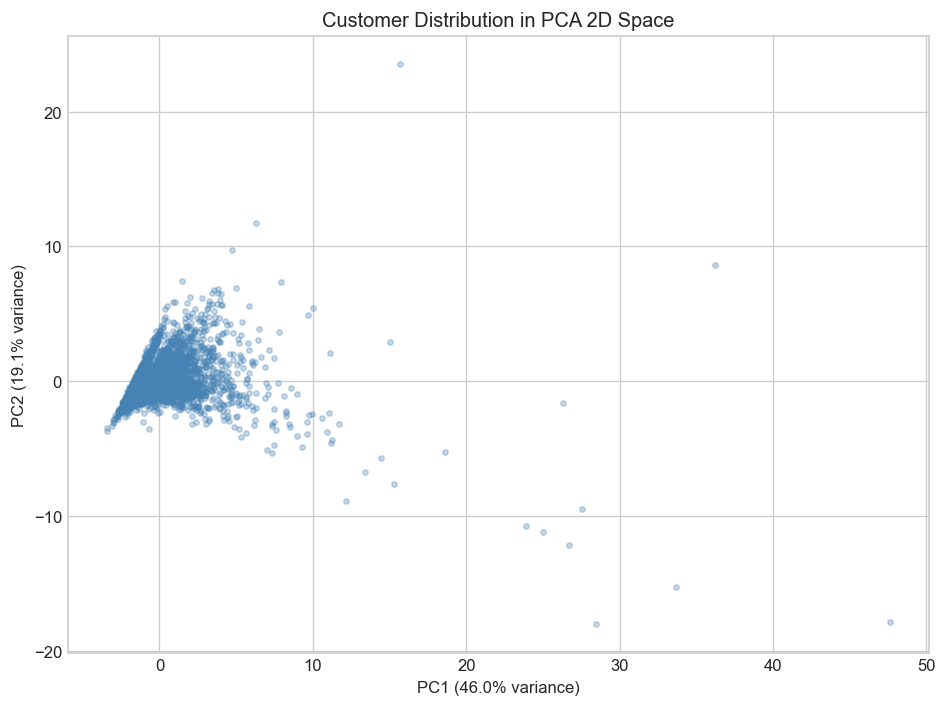

Saved: pca_2d_scatter.png

✅ Saved: features_pca_2d.csv
✅ Saved: features_pca_3d.csv


In [17]:
# ============================================================
# STEP 7: PCA — Dimensionality Reduction
# ============================================================
print("=" * 60)
print("STEP 7: PCA — Dimensionality Reduction")
print("=" * 60)

from sklearn.decomposition import PCA

# ── Full PCA to check explained variance ────────────────────
pca_full = PCA(random_state=42)
pca_full.fit(features_scaled_df)

explained_variance = np.cumsum(pca_full.explained_variance_ratio_)
n_components_90 = np.argmax(explained_variance >= 0.90) + 1
n_components_95 = np.argmax(explained_variance >= 0.95) + 1

print(f"Components to explain 90% variance: {n_components_90}")
print(f"Components to explain 95% variance: {n_components_95}")

print(f"\nIndividual explained variance per PC:")
for i, var in enumerate(pca_full.explained_variance_ratio_):
    bar = '█' * int(var * 100)
    cum = explained_variance[i] * 100
    print(f"  PC{i+1:2d}: {var*100:5.1f}%  cumulative: {cum:5.1f}%  {bar}")

# ── Scree plot ───────────────────────────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.bar(range(1, len(pca_full.explained_variance_ratio_)+1),
        pca_full.explained_variance_ratio_ * 100,
        color='steelblue', alpha=0.8, edgecolor='white')
ax1.set_xlabel('Principal Component')
ax1.set_ylabel('Explained Variance (%)')
ax1.set_title('Scree Plot — Individual Variance per PC')
ax1.set_xticks(range(1, len(pca_full.explained_variance_ratio_)+1))

ax2.plot(range(1, len(explained_variance)+1), explained_variance * 100,
         'o-', color='coral', linewidth=2, markersize=6)
ax2.axhline(y=90, color='gray', linestyle='--', alpha=0.6, label='90%')
ax2.axhline(y=95, color='gray', linestyle=':', alpha=0.6, label='95%')
ax2.axvline(x=n_components_90, color='steelblue', linestyle='--', alpha=0.5)
ax2.axvline(x=n_components_95, color='coral', linestyle='--', alpha=0.5)
ax2.set_xlabel('Number of Components')
ax2.set_ylabel('Cumulative Explained Variance (%)')
ax2.set_title('Cumulative Explained Variance')
ax2.legend()

plt.tight_layout()
plt.savefig('pca_scree_plot.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: pca_scree_plot.png")

# ── PCA 2D (for visualization) ───────────────────────────────
pca_2d = PCA(n_components=2, random_state=42)
features_pca_2d = pca_2d.fit_transform(features_scaled_df)
features_pca_2d_df = pd.DataFrame(features_pca_2d, columns=['PC1', 'PC2'])
print(f"\nPCA 2D — variance explained:")
print(f"  PC1: {pca_2d.explained_variance_ratio_[0]*100:.1f}%")
print(f"  PC2: {pca_2d.explained_variance_ratio_[1]*100:.1f}%")
print(f"  Total: {sum(pca_2d.explained_variance_ratio_)*100:.1f}%")

# ── PCA 3D (for visualization) ───────────────────────────────
pca_3d = PCA(n_components=3, random_state=42)
features_pca_3d = pca_3d.fit_transform(features_scaled_df)
features_pca_3d_df = pd.DataFrame(features_pca_3d, columns=['PC1', 'PC2', 'PC3'])
print(f"\nPCA 3D — variance explained:")
print(f"  PC1: {pca_3d.explained_variance_ratio_[0]*100:.1f}%")
print(f"  PC2: {pca_3d.explained_variance_ratio_[1]*100:.1f}%")
print(f"  PC3: {pca_3d.explained_variance_ratio_[2]*100:.1f}%")
print(f"  Total: {sum(pca_3d.explained_variance_ratio_)*100:.1f}%")

# ── PCA loadings heatmap ─────────────────────────────────────
loadings = pd.DataFrame(
    pca_2d.components_.T,
    index=features_scaled_df.columns,
    columns=['PC1', 'PC2']
)
print(f"\nPC Loadings (which features drive each component):")
print(loadings.round(3).to_string())

plt.figure(figsize=(8, 7))
sns.heatmap(loadings, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            linewidths=0.5, cbar_kws={'shrink': 0.8})
plt.title('PCA Loadings — Feature Contributions to PC1 & PC2', fontsize=13)
plt.tight_layout()
plt.savefig('pca_loadings.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: pca_loadings.png")

# ── 2D scatter preview ───────────────────────────────────────
plt.figure(figsize=(8, 6))
plt.scatter(features_pca_2d_df['PC1'], features_pca_2d_df['PC2'],
            alpha=0.3, s=10, color='steelblue')
plt.xlabel(f"PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}% variance)")
plt.title('Customer Distribution in PCA 2D Space')
plt.tight_layout()
plt.savefig('pca_2d_scatter.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: pca_2d_scatter.png")

# ── Save outputs ─────────────────────────────────────────────
features_pca_2d_df.to_csv('features_pca_2d.csv', index=False)
features_pca_3d_df.to_csv('features_pca_3d.csv', index=False)
print("\n✅ Saved: features_pca_2d.csv")
print("✅ Saved: features_pca_3d.csv")

In [18]:
# Check how bad the outlier is
print("AvgQuantityPerOrder distribution:")
print(df_features['AvgQuantityPerOrder'].describe())
print(f"\nTop 10 values:")
print(df_features['AvgQuantityPerOrder'].nlargest(10).values)

AvgQuantityPerOrder distribution:
count    4242.000000
mean      202.250813
std       174.669321
min         1.000000
25%        90.343750
50%       151.354167
75%       256.000000
max      1383.000000
Name: AvgQuantityPerOrder, dtype: float64

Top 10 values:
[1383.         1359.         1339.28723404 1308.5        1276.
 1248.         1245.         1209.         1187.64835165 1176.57894737]
